# Magic state distillation, level by level

> **In short.**
> * **What this is.** A ZX derivation turns the transversal CCZ of the [[8,3,2]] code around. The distillation identity: the decoder $E^\dagger$ applied to eight magic states ($T$ and $T^\dagger$ on $|+\rangle$) equals $E^\dagger$ applied to $|+\rangle^{\otimes 8}$, followed by a CCZ (the H-box). The decoding derivation: with $E^\dagger$ in normal form, the $|+\rangle$ states copy through it and fuse, which leaves the CCZ applied to $|{+}{+}{+}\rangle$: the three-legged H-box, the CCZ magic state.
> * **Here.** Both sides of the distillation identity as programs, checked equal; then the right-hand side levelled up, one rewrite per level, through the four diagrams of the decoding derivation: `'standard notation'` (the $|+\rangle$ states as green spiders), `'x-z gpf'` ($E^\dagger$ in normal form, an X-spider on each of its inputs, as in the derivation), `'copy and fuse'` (the $|+\rangle$ states copied and fused), `'remove identities'` (the H-box alone). Every level is compared with the circuit, and the last with the left-hand side of the distillation identity.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders, a blue edge a Hadamard, the yellow square an H-box: here the CCZ, $(-1)^{xyz}$ on its three wires.
> * The protocol as it is run, with checks instead of $E^\dagger$'s projections, and why it distils: [MagicStateDistillation.ipynb](MagicStateDistillation.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CCZ, CNOT, T, PostSelect
from zxqec.qprogram import QProgram
from zxqec.gpf import equal_for_all_assignments
from zxqec.spacetime import draw_program, view_levels

# as in TransversalCCZ.ipynb: qubit k is reference qubit [8, 7, 6, 4, 1, 2, 3, 5][k]; x, y, z are qubits 1, 2, 3
WIRES = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 0: 7}          # drawn in the order of the reference drawing
GHZ = [CNOT(0, 4), CNOT(0, 5), CNOT(0, 6), CNOT(0, 7)]
FROM_X = [CNOT(1, 4), CNOT(1, 6), CNOT(1, 7), CNOT(0, 1)]
FROM_Y = [CNOT(2, 4), CNOT(2, 5), CNOT(2, 7), CNOT(0, 2)]
FROM_Z = [CNOT(3, 4), CNOT(3, 5), CNOT(3, 6), CNOT(0, 3)]
# the magic states of the distillation identity: T^dag on reference qubits 1, 4, 6, 7, T on 2, 3, 5, 8
P_DAGGER = [T(1, adjoint=True), T(2, adjoint=True), T(3, adjoint=True), T(4, adjoint=True), T(5), T(6), T(7), T(0)]
# the decoder E^dag: the encoder's CNOTs in reverse order, then each GHZ qubit projected on the state it started in
DECODER = (FROM_Z[::-1] + FROM_Y[::-1] + FROM_X[::-1] + GHZ[::-1]
           + [PostSelect(0, '+')] + [PostSelect(q, '0') for q in (4, 5, 6, 7)])

## The distillation identity

The left-hand side: eight qubits in $|+\rangle$, $T$ or $T^\dagger$ on each, then $E^\dagger$. The right-hand side: $|+\rangle^{\otimes 8}$, $E^\dagger$, then a CCZ on x, y and z (PyZX draws it as an H-box). The derivation obtains it from the transversal CCZ by taking the adjoint; here the tool checks that both sides are the same map, and that it prepares $\mathrm{CCZ}|{+}{+}{+}\rangle$.

left-hand side: deterministic: every run implements prepares CCZ|+++>
both sides the same map: True


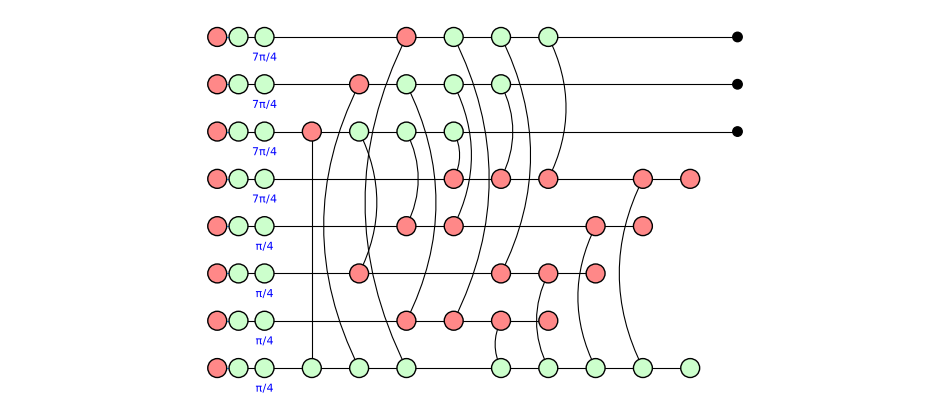

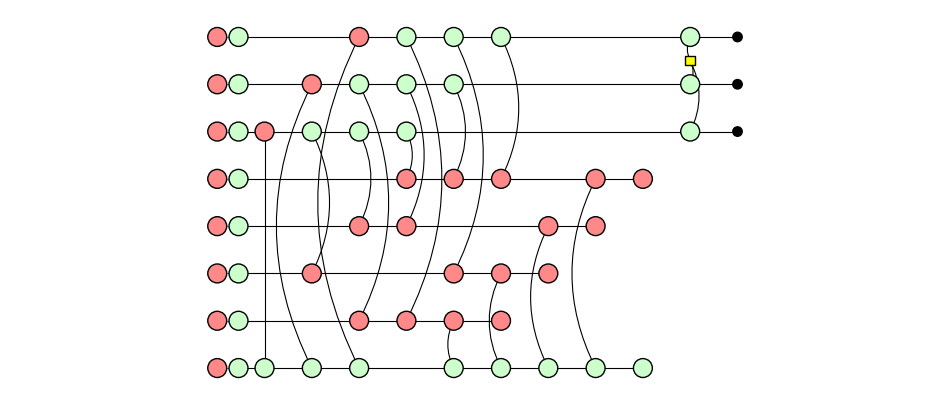

In [2]:
magic = QProgram(8, mapping=WIRES, initial_states={q: '+' for q in range(8)})
decoded = QProgram(8, mapping=WIRES, initial_states={q: '+' for q in range(8)})
for program, stages in ((magic, ((P_DAGGER, 'magic states'), (DECODER, 'decoder'))),
                        (decoded, (([], '|+> states'), (DECODER, 'decoder'), ([CCZ(1, 2, 3)], 'CCZ')))):
    for gates, name in stages:
        c = Circuit(8)
        for gate in gates:
            c.add_gate(gate)
        program.add_circuit(c, name=name)
print("left-hand side:", magic.logical_action().verdict())
print("both sides the same map:", equal_for_all_assignments(magic.quantum_graph(), decoded.quantum_graph()))
display(draw_program(magic, show_time=False, labels=False, figsize=(12, 5)))
draw_program(decoded, show_time=False, labels=False, figsize=(12, 5))

## The decoding derivation, level by level

Four level-ups of the right-hand side, each with one rewrite. `group_stages` makes the first; the others group blocks of the level before.

In [3]:
notation = decoded.group_stages([(0, 0, '|+> states', None, 'standard notation')])
normal_form = decoded.level_up(notation, 1, 1, 'decoder', rewrite='x-z gpf')
copied = decoded.level_up(normal_form, 0, 1, '|+> states and decoder', rewrite='copy and fuse')
h_box = decoded.level_up(copied, 0, 1, 'all', rewrite='remove identities')
for level in (notation, normal_form, copied, h_box):
    print(decoded.describe_level(level), end='\n\n')
circuit_graph = decoded.quantum_graph()

Level 1 (3 blocks):
  Block 0 '|+> states' <rewrite: standard notation>: [|+> states]
  Block 1 'decoder': [decoder]
  Block 2 'CCZ': [CCZ]

Level 2 (3 blocks):
  Block 0 '|+> states' <rewrite: standard notation>: [|+> states]
  Block 1 'decoder' <rewrite: x-z gpf>: [decoder]
  Block 2 'CCZ': [CCZ]

Level 3 (2 blocks):
  Block 0 '|+> states and decoder' <rewrite: copy and fuse>: [|+> states, decoder]
  Block 1 'CCZ': [CCZ]

Level 4 (1 blocks):
  Block 0 'all' <rewrite: remove identities>: [|+> states, decoder, CCZ]



### Level 1: the $|+\rangle$ states

`'standard notation'` on the first stage: PyZX's $|+\rangle$, a $|0\rangle$ behind a Hadamard edge, becomes a green spider with one leg. The derivation draws $E^\dagger$ as a box; here it is the circuit.

|+> states (1 children): 16 spiders -> 8 after rewrite standard notation
the same map as the circuit: True


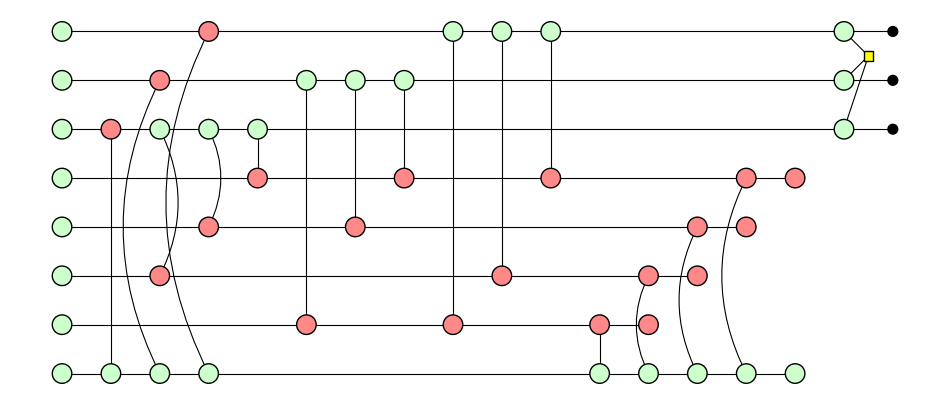

In [4]:
print(decoded.reduced_block(notation, 0))
level = decoded.reduced_level(notation)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(12, 5))

### Level 2: $E^\dagger$ in normal form

`'x-z gpf'` on the decoder: the normal form with an X-spider on each of its eight inputs and a Z-spider for each of x, y and z, plus one inside for the encoder's random bit $w$, as the adjoint of the encoder's Z-X normal form is.

decoder (1 children): 37 spiders -> 12 after rewrite x-z gpf
the same map as the circuit: True


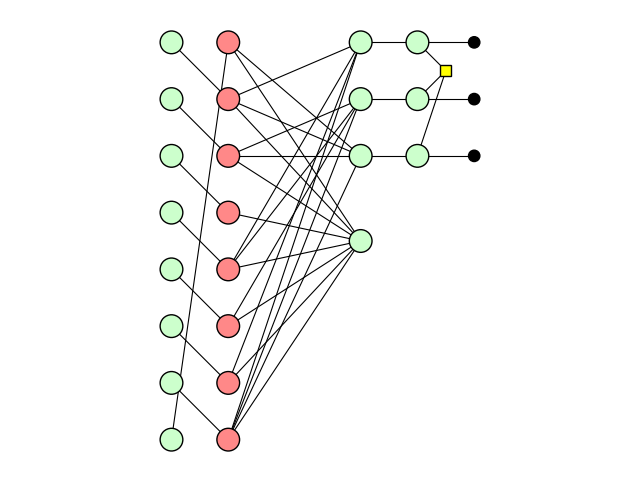

In [5]:
print(decoded.reduced_block(normal_form, 1))
level = decoded.reduced_level(normal_form)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(8, 6))

### Level 3: the $|+\rangle$ states copy and fuse

`'copy and fuse'` on the $|+\rangle$ states and the decoder: each green $|+\rangle$ is copied through the red X-spider it meets, onto the Z-spiders of x, y, z and $w$, and the copies fuse into them. x, y and z are left in $|+\rangle$; the spider of $w$, with nothing left on it but copies, becomes a number.

|+> states and decoder (2 children): 20 spiders -> 3 after rewrite copy and fuse
the same map as the circuit: True


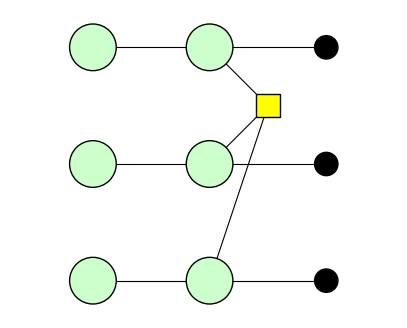

In [6]:
print(decoded.reduced_block(copied, 0))
level = decoded.reduced_level(copied)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(5, 4))

### Level 4: the three-legged H-box

`'remove identities'` on everything: each $|+\rangle$ fuses into the green spider of the CCZ on its wire, which then has two legs and no phase and is removed. What is left is the H-box with three legs, the CCZ magic state, the same map as the eight magic states decoded (the left-hand side of the distillation identity).

all (2 children): 7 spiders -> 1 after rewrite remove identities
the same map as the circuit: True
the same map as the magic states decoded: True


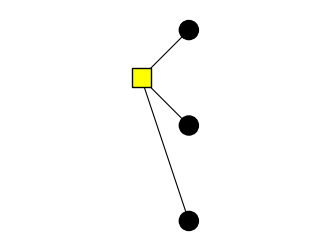

In [7]:
print(decoded.reduced_block(h_box, 0))
level = decoded.reduced_level(h_box)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
print("the same map as the magic states decoded:", equal_for_all_assignments(magic.quantum_graph(), level.graph))
zx.draw_matplotlib(level.graph, figsize=(4, 3))

## The levels window

`view_levels` shows a level: its blocks outlined in the circuit (those they were made from dashed), the circuit as the level rewrites it, and the selected block. Here, level 2.

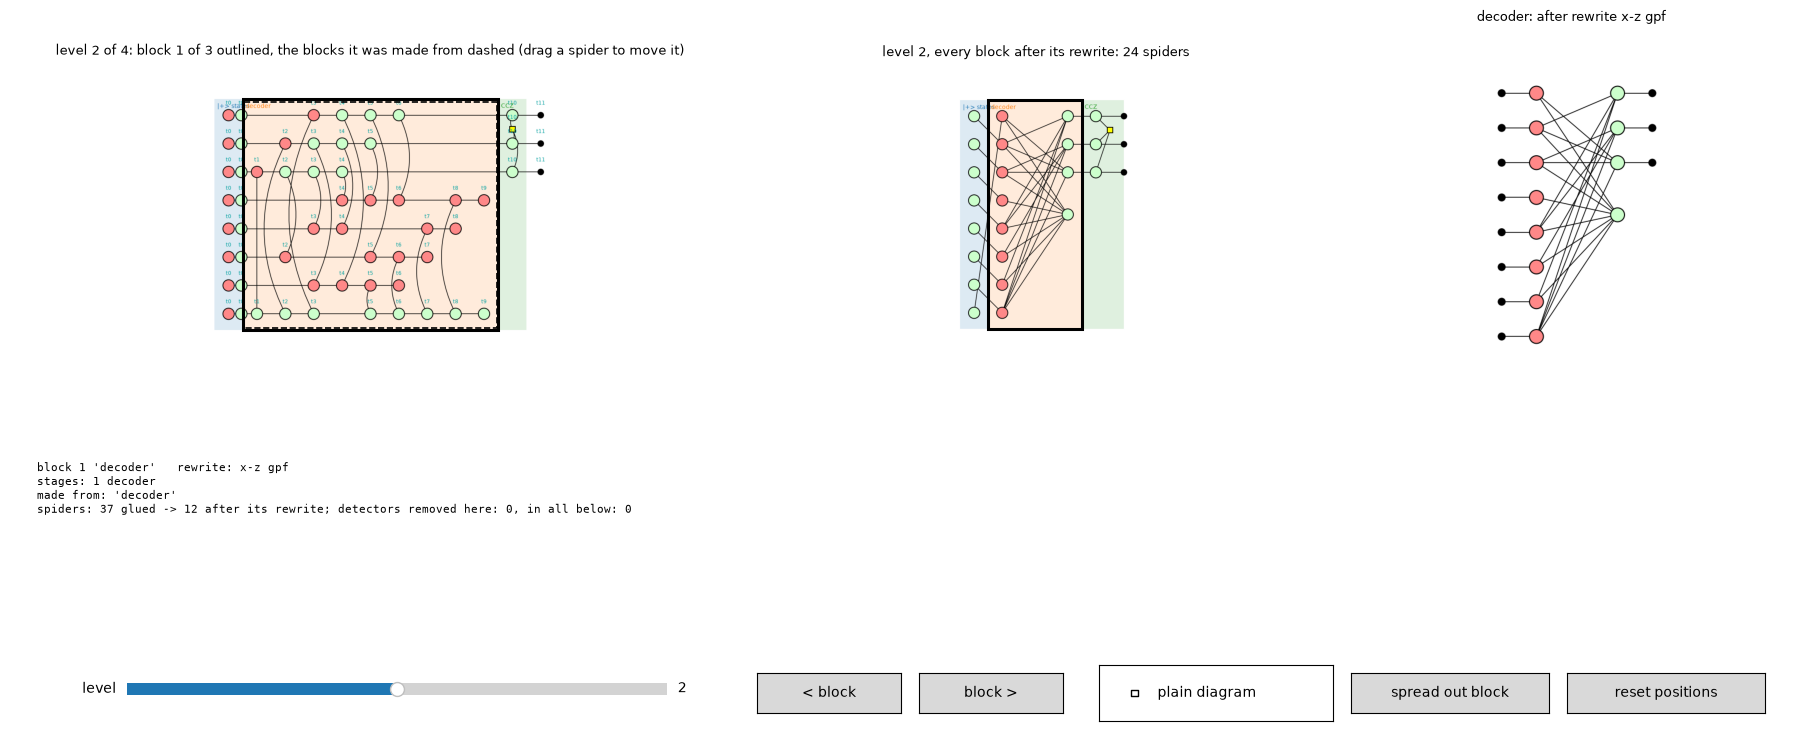

In [8]:
window = view_levels(decoded, normal_form, 1)

## How this differs from the derivation

* The distillation identity is checked, not rewritten: the derivation gets it from the transversal CCZ by taking the adjoint, and the transversal CCZ is level by level in [TransversalCCZStepByStep.ipynb](TransversalCCZStepByStep.ipynb).
* The derivation draws $E^\dagger$ as a box in its first diagram; here it is its circuit: the encoder's CNOTs in reverse order and the projections of the GHZ qubits.
* In its third diagram the derivation still draws the spider of $w$ with the eight copies on it; here they are fused into a number at once.
* The pictures are PyZX's drawings at the positions the rewrites give the spiders.

What is not covered: the projections of $E^\dagger$ are not something a protocol can do; it measures instead and keeps the runs whose results are 0, as in [MagicStateDistillation.ipynb](MagicStateDistillation.ipynb).